**PoCT - Toxoplasmosis Diagnosis Device (Dec, 2026)**  
Dodit Suprianto  
Email: Dodit.suprianto@polinema.ac.id  
Affiliation:  
- Department of Electrical Engineering, Politeknik Negeri Malang, Malang, Indonesia  
- AIDS, Toxoplasma, Opportunistic Disease and Malaria (ATOM) Research Group, Faculty of Medicine, Universitas Brawijaya, Malang, Indonesia

---

# YOLOv8-seg spot segmentation for the anti-GRA7 dot-blot reader: audited dataset, training and validation

**Purpose.** This notebook documents the instance-segmentation stage of the dot-blot reader (detection and delineation of every spot on a membrane image before cropping and quantification). It replaces the earlier working notebook (*Segmentasi Dotblot.ipynb*) with a version that is **reproducible, audited and reports its metrics in a verifiable way**.

**What is different from the working notebook**

| Issue in the working notebook | Handling here |
|---|---|
| Data prepared by rewriting `Train`/`Validation` list files on Drive | The dataset folders are read in place; a clean working copy with `images/<split>` and `labels/<split>` is built in a temporary folder, the original dataset is never modified |
| No check that labels match images, no leakage check | Section 3: orphan labels, unlabelled images, malformed polygons, duplicates across splits (SHA-256) |
| `model.val()` after training was run at the default 640 px although training used 1920 px (numbers differ) | Validation always uses the training `imgsz`; the effect of `imgsz` is shown explicitly (Section 9) |
| Metrics copied from the last epoch of the training log | Metrics of the **saved `best.pt` and `last.pt`** are reported separately; `best.pt` is selected on the validation split, so its metrics are optimistic and are flagged as such |
| "0 false positives / 0 false negatives" not computed anywhere | Section 8 counts TP/FP/FN **per spot at the mask level** (IoU ≥ 0.5, one-to-one matching) at several confidence thresholds and lists every failure |
| Approximate spot counts per image | Exact instance counts per split and per image (Sections 2 and 6) |

**Pipeline**

| Step | Content |
|---|---|
| 1 | Setup and configuration |
| 2 | Extraction and dataset inventory |
| 3 | Label-placement diagnosis, duplicates / leakage |
| 4 | Clean working copy and `data.yaml` |
| 5 | Visual verification of labels |
| 6 | Exploratory analysis (instances per image, spot size, spatial layout) |
| 7 | Training (YOLOv8n-seg, COCO-pretrained; configuration used for the manuscript) |
| 8 | Validation: Ultralytics metrics and spot-level TP/FP/FN |
| 9 | Resolution sensitivity and F1–confidence |
| 10 | Qualitative inspection |
| 11 | Optional grouped K-fold cross-validation |
| 12 | Inference and cropping (circular ROI, 5% radial padding, greyscale) |
| 13 | Manuscript-ready summary |

## 1. Setup and configuration

In [1]:
try:
    import ultralytics
except ImportError:
    %pip -q install "ultralytics==8.4.208"

import os, sys, json, hashlib, random, shutil, platform, warnings, zipfile, tempfile
from pathlib import Path
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

# ----------------------------- CONFIGURATION -----------------------------
# Paths are NOT hard-coded: see _find_root() below. To run elsewhere, set DOTBLOT_YOLO_ROOT (and optionally DOTBLOT_OUT_DIR, DOTBLOT_TRAIN).
try:                                   # Colab only: mount Drive; elsewhere the local folders are used
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass
def _find_root():
    # Resolution order: (1) environment variable DOTBLOT_YOLO_ROOT, (2) Colab Drive folder, (3) current folder, its sub-folder or parent.
    # ROOT is the folder that contains dataset/train, dataset/validation and dataset/test ("DotBlot YOLO Segmentation" in the repository).
    env = os.environ.get('DOTBLOT_YOLO_ROOT')
    cands = [Path(env)] if env else []
    cands += [Path('/content/drive/MyDrive/DotBlot YOLO Segmentation'), Path('/content/drive/MyDrive/DotBlot FKUB'),
              Path.cwd(), Path.cwd()/'DotBlot YOLO Segmentation', Path.cwd().parent]
    for c in cands:
        if (c/'dataset'/'train'/'images').exists() and (c/'dataset'/'validation'/'images').exists(): return c
    raise FileNotFoundError('Dataset not found. Set the environment variable DOTBLOT_YOLO_ROOT to the folder that contains dataset/train and dataset/validation.')
ROOT       = _find_root()
TRAIN_DIR  = ROOT/'dataset'/'train'                      # images/Train + labels/Train (Ultralytics segmentation format)
VAL_DIR    = ROOT/'dataset'/'validation'                 # images/Validation + labels/Validation
TEST_DIR   = ROOT/'dataset'/'test'                       # qualitative test images (full membrane photographs)
_TMP       = Path(os.environ.get('DOTBLOT_TMP', tempfile.gettempdir()))/'dotblot'
WORK_DIR   = _TMP/'clean'                                # corrected working copy (temporary; the dataset folder is never written to)
PUBLISHED  = ROOT/'yolo_results'                         # results reported in the manuscript (reference, not overwritten)
OUT_DIR    = Path(os.environ.get('DOTBLOT_OUT_DIR', ROOT/'yolo_results_rerun'))   # re-runs are written here
RUN_TRAINING = os.environ.get('DOTBLOT_TRAIN', '1') == '1'   # '0' = skip Section 7 and evaluate the published weights (yolo_results/<RUN_NAME>/weights)
RUN_NAME   = 'dotblot-yolov8n-seg'

MODEL      = 'yolov8n-seg.pt'                            # COCO-pretrained checkpoint
CLASS_NAME = 'circle'                                    # single class
SEED       = 0

# Training configuration used for the manuscript (as in the working notebook, cell "imgsz=1920").
# NOTE: the working notebook also set cos_lr=True; this was not listed in the earlier supplementary table.
TRAIN_CFG = dict(epochs=50, imgsz=1920, batch=4, workers=1, optimizer='AdamW', lr0=0.0005, weight_decay=0.0001,
                 warmup_epochs=5, cos_lr=True, amp=False, seed=SEED, deterministic=True, plots=True)
IMGSZ = TRAIN_CFG['imgsz']

BACKGROUND_OK      = []     # stems of images CONFIRMED to contain no spot (Section 5)
EXCLUDE_UNRESOLVED = True   # unlabelled images not in BACKGROUND_OK are left out of the working copy
RUN_KFOLD          = False  # Section 11 (optional, slow)
# --------------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(platform.platform()); print('Python', sys.version.split()[0])
import ultralytics, torch
print('Ultralytics', ultralytics.__version__, '| torch', torch.__version__, '| CUDA', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Linux-6.6.159+-x86_64-with-glibc2.39
Python 3.13.16
Ultralytics 8.4.208 | torch 2.14.1+cu130 | CUDA True | Tesla T4


## 2. Extraction and dataset inventory

The two dataset folders (`dataset/train`, `dataset/validation`) are read in place, without extraction. Because the folder layout is not assumed, images and label files are **discovered recursively** and paired **by file stem within the same split**. A text file counts as a label file only if every non-empty line is `class_id x1 y1 x2 y2 x3 y3 …` (at least three points); list files such as `Train.txt` are therefore ignored. For every image the code records the number of polygons, polygon validity, image size and a SHA-256 hash.

In [2]:
IMG_EXT = {'.png', '.jpg', '.jpeg', '.bmp'}
def sha256(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()

SRC_DIRS = {'train': TRAIN_DIR, 'val': VAL_DIR}      # the dataset is read in place (no extraction, originals untouched)

def read_label(path):
    # Return (list of Nx2 polygons in normalised coordinates, all_lines_valid). A line is valid if it is a class id plus >=3 x-y pairs.
    polys, ok = [], True
    for ln in Path(path).read_text().splitlines():
        t = ln.split()
        if not t: continue
        try:
            int(t[0]); vals = np.array(t[1:], dtype=float)
        except ValueError:
            return [], False
        if len(vals) < 6 or len(vals) % 2: ok = False; continue
        polys.append(vals.reshape(-1, 2))
    return polys, ok

def is_label_file(p):
    lines = [l for l in Path(p).read_text().splitlines() if l.strip()]
    if not lines: return True            # empty label file = background image
    try:
        for l in lines:
            t = l.split(); int(t[0]); [float(x) for x in t[1:]]
        return True
    except Exception:
        return False

rows, label_files, dup_stems = [], {}, []
for sp in ('train', 'val'):
    root = SRC_DIRS[sp]
    imgs, labs = {}, {}
    for p in sorted(root.rglob('*')):
        if p.is_dir(): continue
        if p.suffix.lower() in IMG_EXT:
            if p.stem in imgs: dup_stems.append((sp, p.stem))
            imgs[p.stem] = p
        elif p.suffix.lower() == '.txt' and p.name.lower() not in ('classes.txt', 'labels.txt') and is_label_file(p):
            labs[p.stem] = p
    label_files[sp] = labs
    for stem, p in imgs.items():
        lab = labs.get(stem); n, ok = 0, True
        if lab is not None: polys, ok = read_label(lab); n = len(polys)
        g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE); h, w = g.shape
        rows.append(dict(split=sp, stem=stem, path=str(p), has_label=lab is not None, n_inst=n, valid=ok, w=w, h=h, sha=sha256(p)))
inv = pd.DataFrame(rows)
print('Duplicate file stems inside a split (should be empty):', dup_stems)
summary = inv.groupby('split').agg(images=('stem','count'), with_label_file=('has_label','sum'),
                                   instances=('n_inst','sum'), no_instance=('n_inst', lambda x: int((x==0).sum())),
                                   min_per_image=('n_inst','min'), median_per_image=('n_inst','median'), max_per_image=('n_inst','max'))
display(summary)
print('Malformed label files:', int((~inv.valid).sum()))
print('Image size (px): width %d-%d, height %d-%d' % (inv.w.min(), inv.w.max(), inv.h.min(), inv.h.max()))
print('Image-size combinations:'); display(inv.groupby(['w','h']).size().rename('n').reset_index())

Duplicate file stems inside a split (should be empty): []


,images,with_label_file,instances,no_instance,min_per_image,median_per_image,max_per_image
split,,,,,,,
train,85,85,1090,0,2,13.0,24
val,39,39,525,0,4,14.0,25


Malformed label files: 0
Image size (px): width 3840-3840, height 2160-2160
Image-size combinations:


,w,h,n
0,3840,2160,124


## 3. Label-placement diagnosis and leakage checks

* **Orphan labels** – a label whose image is not in the same split. If the image exists in the other split the label is *misplaced*, and Ultralytics would treat that image as background (every correct detection then counts as a false positive).
* **Unlabelled images** – images with no label file or no polygon.
* **Duplicates across splits** – identical image files in training and validation inflate the metrics.
* **Overlap with the qualitative test folder.**

In [3]:
orph = []
for sp, other in (('train','val'), ('val','train')):
    here = set(inv.loc[inv.split==sp, 'stem']); there = set(inv.loc[inv.split==other, 'stem'])
    for stem in label_files[sp]:
        if stem not in here: orph.append(dict(label_in=sp, stem=stem, image_in=(other if stem in there else 'nowhere')))
orph = pd.DataFrame(orph, columns=['label_in','stem','image_in'])
print('Orphan labels:', len(orph)); display(orph.groupby(['label_in','image_in']).size().rename('n').reset_index()) if len(orph) else None

unl = inv[(~inv.has_label) | (inv.n_inst == 0)]
print('Images without a usable label in their own split:'); display(unl.groupby('split').size().rename('n').reset_index())

dup = inv.groupby('sha').filter(lambda g: len(g) > 1)
cross = [g for _, g in dup.groupby('sha') if g.split.nunique() > 1]
print(f'Duplicate groups: {dup.sha.nunique()} | files: {len(dup)} | groups crossing train/val: {len(cross)}')
display(dup.sort_values('sha')[['split','stem']].assign(sha=dup.sort_values('sha').sha.str[:10]))

if TEST_DIR.exists():
    th = {sha256(p): p.name for p in TEST_DIR.glob('*') if p.suffix.lower() in IMG_EXT}
    ov = inv[inv.sha.isin(th)]
    print(f'Test images identical to a training/validation image: {ov.sha.nunique()} of {len(th)}',
          '(use them as illustrations only)' if len(ov) else '')

Orphan labels: 0
Images without a usable label in their own split:


,split,n


Duplicate groups: 0 | files: 0 | groups crossing train/val: 0


,split,stem,sha


Test images identical to a training/validation image: 0 of 11 


## 4. Corrected working copy

The original **split assignment is preserved**. Only demonstrable problems are corrected, and every action is logged:

1. a label found in the other split folder is attached to its image;
2. images that still have no label are excluded unless their stem is in `BACKGROUND_OK` (confirmed blanks);
3. one member of each cross-split duplicate pair is dropped from validation.

In [4]:
if WORK_DIR.exists(): shutil.rmtree(WORK_DIR)
for sp in ('train','val'):
    (WORK_DIR/'images'/sp).mkdir(parents=True); (WORK_DIR/'labels'/sp).mkdir(parents=True)
all_labels = {}
for sp in label_files: all_labels.update(label_files[sp])
drop_val = {r.stem for g in cross for r in g.itertuples() if r.split=='val'}

log, kept = [], []
for r in inv.itertuples():
    if r.split=='val' and r.stem in drop_val:
        log.append((r.split, r.stem, 'dropped: duplicate of a training image')); continue
    lab = label_files[r.split].get(r.stem); source = 'own split'
    if lab is None and r.stem in all_labels: lab, source = all_labels[r.stem], 'moved from other split'
    has = lab is not None and len(read_label(lab)[0]) > 0
    if not has and r.stem not in BACKGROUND_OK and EXCLUDE_UNRESOLVED:
        log.append((r.split, r.stem, 'excluded: no label')); continue
    ext = Path(r.path).suffix
    shutil.copy2(r.path, WORK_DIR/'images'/r.split/f'{r.stem}{ext}')
    dst = WORK_DIR/'labels'/r.split/f'{r.stem}.txt'
    shutil.copy2(lab, dst) if has else dst.write_text('')
    kept.append(dict(split=r.split, stem=r.stem, ext=ext, n_inst=len(read_label(dst)[0]), label_source=source if has else 'confirmed background'))
kept = pd.DataFrame(kept); log = pd.DataFrame(log, columns=['split','stem','action'])
(WORK_DIR/'data.yaml').write_text(f"path: {WORK_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: {CLASS_NAME}\n")

comp = kept.groupby('split').agg(images=('stem','count'), annotated_spots=('n_inst','sum'),
                                 background_images=('n_inst', lambda x: int((x==0).sum())))
comp['spots_per_image_mean'] = (comp.annotated_spots/comp.images).round(2)
comp['image_share_%'] = (100*comp.images/comp.images.sum()).round(1)
display(comp); print('Label provenance:'); display(kept.groupby(['split','label_source']).size().rename('n').reset_index())
print('Actions on images not carried over unchanged:'); display(log)
inv.drop(columns='path').to_csv(OUT_DIR/'dataset_inventory.csv', index=False)
kept.to_csv(OUT_DIR/'dataset_corrected_composition.csv', index=False); log.to_csv(OUT_DIR/'dataset_corrections_log.csv', index=False)

,images,annotated_spots,background_images,spots_per_image_mean,image_share_%
split,,,,,
train,85,1090,0,12.82,68.5
val,39,525,0,13.46,31.5


Label provenance:


,split,label_source,n
0,train,own split,85
1,val,own split,39


Actions on images not carried over unchanged:


,split,stem,action


## 5. Visual verification of labels

Random labelled images with their polygons, followed by every image that has no label. An unlabelled image that shows spots must be annotated before use; a truly blank image can be added to `BACKGROUND_OK` (Section 1) and Sections 4 onward re-run.

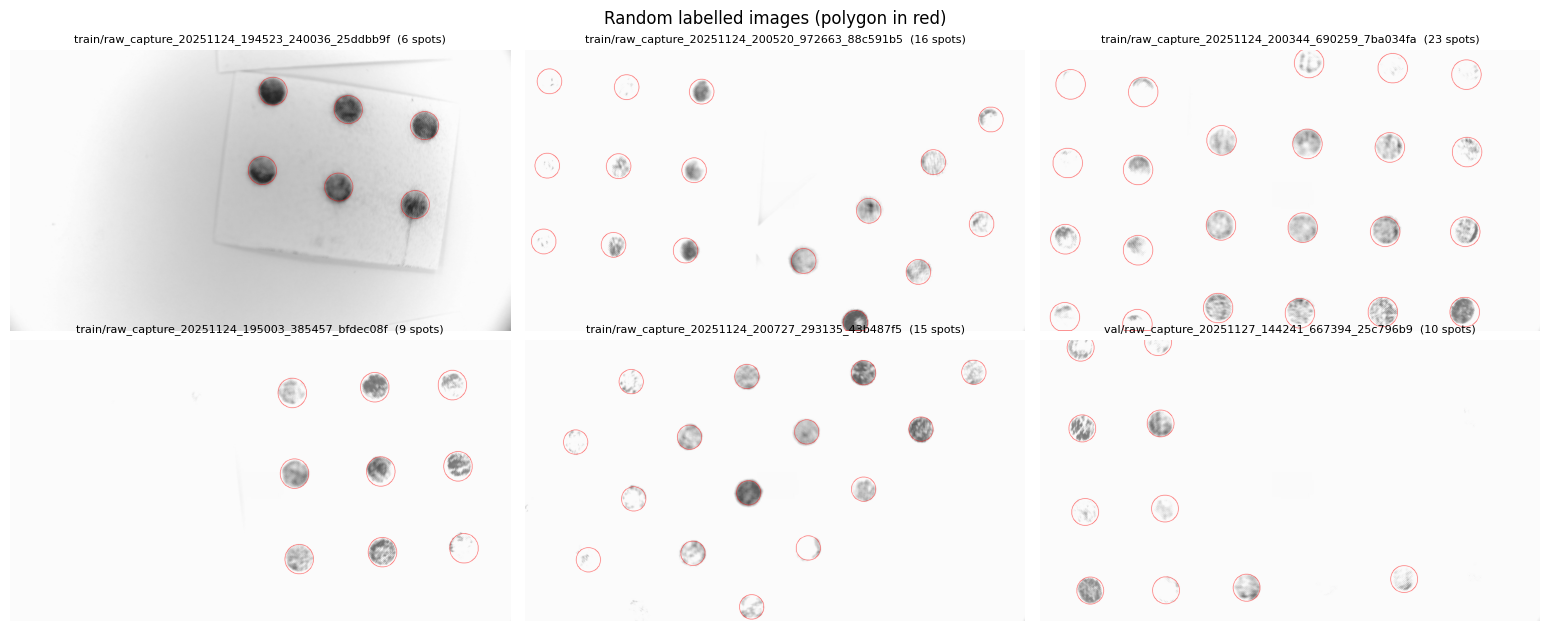

Every image has a label or is a confirmed background image.


In [5]:
def img_path(split, stem):
    r = kept[(kept.split==split)&(kept.stem==stem)].iloc[0]; return WORK_DIR/'images'/split/f'{stem}{r.ext}'
def overlay(path, lab_path=None, color=(255,0,0), th=2):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE); im = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB); h, w = g.shape
    if lab_path is not None and Path(lab_path).exists():
        for poly in read_label(lab_path)[0]:
            cv2.polylines(im, [(poly*[w,h]).astype(np.int32)], True, color, th)
    return im
def grid(items, title, ncols=3, size=(5.2,3.2)):
    nrows = int(np.ceil(len(items)/ncols)); fig, axes = plt.subplots(nrows, ncols, figsize=(size[0]*ncols, size[1]*nrows)); axes = np.atleast_2d(axes)
    for ax in axes.ravel(): ax.axis('off')
    for ax, (im, cap) in zip(axes.ravel(), items): ax.imshow(im); ax.set_title(cap, fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

smp = kept[kept.n_inst>0].sample(min(6, (kept.n_inst>0).sum()), random_state=SEED)
grid([(overlay(img_path(r.split, r.stem), WORK_DIR/'labels'/r.split/f'{r.stem}.txt'), f'{r.split}/{r.stem}  ({r.n_inst} spots)') for r in smp.itertuples()],
     'Random labelled images (polygon in red)')
un = log[log.action.str.startswith('excluded')]
if len(un):
    grid([(overlay(inv.loc[(inv.split==r.split)&(inv.stem==r.stem),'path'].iloc[0]), f'{r.split}/{r.stem}') for r in un.itertuples()][:12], 'Images WITHOUT a label: annotate or confirm as blank')
else: print('Every image has a label or is a confirmed background image.')

## 6. Exploratory analysis

Spots per image, equivalent spot diameter and the spatial layout of the annotated spots (all training polygons in normalised image coordinates). A near-regular grid confirms that the labels follow the 2 × 2-block layout of the membranes.

split            train      val
diam_px count   1090.0    525.0
        mean     205.4    192.5
        std       19.1     15.0
        min      114.0    107.9
        25%      189.4    186.5
        50%      213.5    195.5
        75%      222.5    195.5
        max      228.6    214.6
area_px count   1090.0    525.0
        mean   33428.6  29279.0
        std     5948.5   4160.7
        min    10201.5   9146.6
        25%    28181.0  27332.1
        50%    35811.4  30008.5
        75%    38871.0  30008.7
        max    41037.1  36170.2

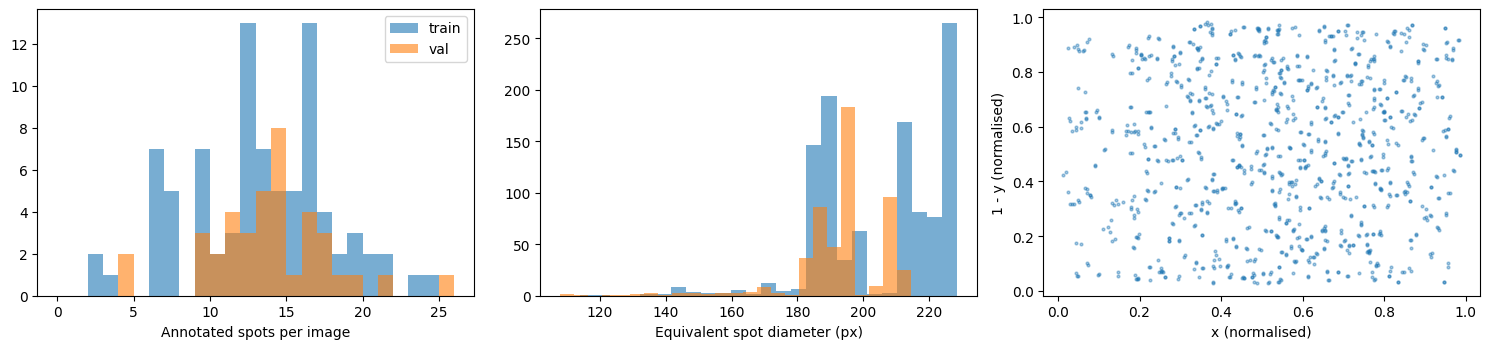

In [6]:
recs = []
for r in kept[kept.n_inst>0].itertuples():
    g = cv2.imread(str(img_path(r.split, r.stem)), cv2.IMREAD_GRAYSCALE); h, w = g.shape
    for poly in read_label(WORK_DIR/'labels'/r.split/f'{r.stem}.txt')[0]:
        x, y = poly[:,0]*w, poly[:,1]*h
        a = 0.5*abs(np.dot(x, np.roll(y,1)) - np.dot(y, np.roll(x,1)))
        recs.append(dict(split=r.split, stem=r.stem, img_w=w, img_h=h, area_px=a, diam_px=2*np.sqrt(a/np.pi),
                         cx=x.mean()/w, cy=y.mean()/h, bbox_w=np.ptp(x), bbox_h=np.ptp(y)))
sp_df = pd.DataFrame(recs)
display(sp_df.groupby('split')[['diam_px','area_px']].describe().T.round(1))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for s, g in kept.groupby('split'): ax[0].hist(g.n_inst, bins=range(0, int(kept.n_inst.max())+2), alpha=.6, label=s)
ax[0].set_xlabel('Annotated spots per image'); ax[0].legend()
for s, g in sp_df.groupby('split'): ax[1].hist(g.diam_px, bins=25, alpha=.6, label=s)
ax[1].set_xlabel('Equivalent spot diameter (px)')
t = sp_df[sp_df.split=='train']; ax[2].scatter(t.cx, 1-t.cy, s=4, alpha=.4); ax[2].set_xlabel('x (normalised)'); ax[2].set_ylabel('1 - y (normalised)')
plt.tight_layout(); plt.show()
sp_df.to_csv(OUT_DIR/'annotated_spot_statistics.csv', index=False)

## 7. Training

The model is the COCO-pretrained `yolov8n-seg.pt`; because `data.yaml` declares one class the 80-class output layer is re-initialised for a single class. The configuration is `TRAIN_CFG` (Section 1): 1920-px input, batch 4, AdamW with a lower learning rate, 5 warm-up epochs, cosine learning-rate schedule, no mixed precision. All other settings are Ultralytics defaults and are stored in `args.yaml` of the run. The default on-line augmentation is active (mosaic, HSV jitter, horizontal flip, scale/translation, random erasing, and – when the Albumentations package is installed – low-probability blur, median blur, grey-scale conversion and CLAHE; the log line starting with `albumentations:` documents the latter).

Before training, verify in the log that **the number of training and validation images and the absence of background images match the table of Section 4**.

In [7]:
from ultralytics import YOLO
if RUN_TRAINING:
    model = YOLO(MODEL)
    train_res = model.train(data=str(WORK_DIR/'data.yaml'), project=str(OUT_DIR), name=RUN_NAME, exist_ok=True, **TRAIN_CFG)
    RUN_DIR = Path(train_res.save_dir)
else:   # evaluation-only mode: use the weights published with the manuscript (set DOTBLOT_TRAIN=1 to train from scratch)
    RUN_DIR = PUBLISHED/RUN_NAME
    assert (RUN_DIR/'weights'/'best.pt').exists(), f'No weights found in {RUN_DIR}/weights'
print('Run directory:', RUN_DIR)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dotblot_clean/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1920, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=dotblot-yolov8n-seg, nbs=64, nms=None, opset=None, 

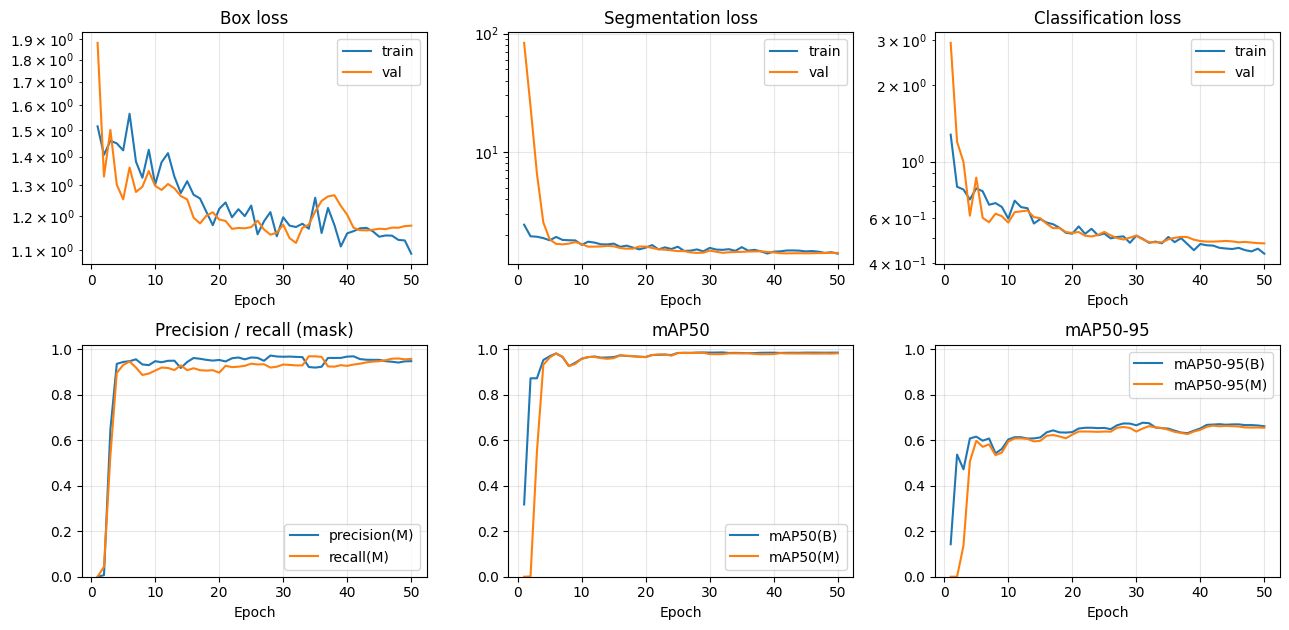

Epoch with the highest validation mask mAP50-95 (= best.pt): 42


In [8]:
res = pd.read_csv(RUN_DIR/'results.csv'); res.columns = [c.strip() for c in res.columns]
fig, ax = plt.subplots(2, 3, figsize=(13, 6.4))
for a, (t, cols) in zip(ax[0], [('Box loss',['train/box_loss','val/box_loss']),('Segmentation loss',['train/seg_loss','val/seg_loss']),('Classification loss',['train/cls_loss','val/cls_loss'])]):
    for c in cols: a.plot(res['epoch'], res[c], label=c.split('/')[0])
    a.set_title(t); a.legend(); a.set_yscale('log')
for a, (t, cols) in zip(ax[1], [('Precision / recall (mask)',['metrics/precision(M)','metrics/recall(M)']),('mAP50',['metrics/mAP50(B)','metrics/mAP50(M)']),('mAP50-95',['metrics/mAP50-95(B)','metrics/mAP50-95(M)'])]):
    for c in cols: a.plot(res['epoch'], res[c], label=c.split('metrics/')[1])
    a.set_title(t); a.legend(); a.set_ylim(0, 1.02)
for a in ax.ravel(): a.set_xlabel('Epoch'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR/f'{RUN_NAME}_training_curves.png', dpi=200); plt.show()
bi = int(res['metrics/mAP50-95(M)'].idxmax()); print('Epoch with the highest validation mask mAP50-95 (= best.pt):', int(res.loc[bi,'epoch']))

## 8. Validation

All numbers refer to the held-out validation split of the corrected dataset and to the **training resolution** (`imgsz = IMGSZ`).

1. **Ultralytics metrics** for `best.pt` and `last.pt`. Precision and recall are given at the confidence that maximises F1; mAP is integrated over all confidences. `best.pt` is selected on this same validation split, so its metrics are optimistic; `last.pt` is the unselected final model and should be quoted alongside it.
2. **Spot-level counts** at a deployment confidence threshold: every predicted mask is matched one-to-one to a ground-truth mask (mask IoU ≥ 0.5, greedy by IoU). This yields true positives, false positives and false negatives for each image and makes statements such as “all spots were detected” directly verifiable.

In [9]:
def ultra_metrics(weights, name):
    m = YOLO(weights).val(data=str(WORK_DIR/'data.yaml'), split='val', imgsz=IMGSZ, plots=True, project=str(OUT_DIR), name=name, exist_ok=True, verbose=False)
    t = pd.DataFrame({'precision':[m.box.mp, m.seg.mp], 'recall':[m.box.mr, m.seg.mr], 'mAP50':[m.box.map50, m.seg.map50], 'mAP50-95':[m.box.map, m.seg.map]}, index=['Box','Mask']).round(3)
    try:
        f1 = m.seg.f1_curve.mean(0); k = int(np.argmax(f1)); peak = (round(float(f1[k]),3), round(float(m.seg.px[k]),3))
    except Exception: peak = None
    return m, t, peak
m_best, t_best, f1_best = ultra_metrics(RUN_DIR/'weights'/'best.pt', RUN_NAME+'_val_best')
m_last, t_last, f1_last = ultra_metrics(RUN_DIR/'weights'/'last.pt', RUN_NAME+'_val_last')
print('best.pt'); display(t_best); print('mask F1 peak (F1, confidence):', f1_best)
print('last.pt'); display(t_last); print('mask F1 peak (F1, confidence):', f1_last)
pd.concat({'best':t_best,'last':t_last}).to_csv(OUT_DIR/f'{RUN_NAME}_validation_metrics.csv')

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3763.5±152.8 MB/s, size: 24341.3 KB)
val: Scanning /content/dotblot_clean/labels/val.cache... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 9.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.8s/it 14.4s
                   all         39        525      0.965      0.935      0.987      0.676      0.963      0.933      0.979      0.663
Speed: 25.7ms preprocess, 32.1ms inference, 0.0ms loss, 11.7ms postprocess per image
Results saved to /content/drive/MyDrive/DotBlot FKUB/yolo_results/dotblot-yolov8n-seg_val_best
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,3

,precision,recall,mAP50,mAP50-95
Box,0.965,0.935,0.987,0.676
Mask,0.963,0.933,0.979,0.663


mask F1 peak (F1, confidence): (0.949, 0.528)
last.pt


,precision,recall,mAP50,mAP50-95
Box,0.947,0.960,0.986,0.664
Mask,0.954,0.956,0.983,0.655


mask F1 peak (F1, confidence): (0.955, 0.464)


In [10]:
best = YOLO(RUN_DIR/'weights'/'best.pt')
val_names = sorted(p for p in (WORK_DIR/'images'/'val').iterdir() if p.suffix.lower() in IMG_EXT)

def poly_int(poly_px): return np.round(poly_px).astype(np.int32)      # integer pixel polygon (what cv2.fillPoly rasterises)
def mask_iou(a, b, h, w):
    # IoU of two polygon masks. Both are rasterised only inside their joint bounding box (clipped to the image), which gives exactly the
    # same pixel counts as full-image rasters (3,840 x 2,160 px each) but needs about 1,000 times less memory: storing full rasters of
    # all predicted and annotated spots of 39 images needs > 10 GB of RAM.
    x0, x1 = max(min(a[:,0].min(), b[:,0].min()), 0), min(max(a[:,0].max(), b[:,0].max()), w-1)
    y0, y1 = max(min(a[:,1].min(), b[:,1].min()), 0), min(max(a[:,1].max(), b[:,1].max()), h-1)
    if x1 < x0 or y1 < y0: return 0.0
    if a[:,0].max()<b[:,0].min() or b[:,0].max()<a[:,0].min() or a[:,1].max()<b[:,1].min() or b[:,1].max()<a[:,1].min(): return 0.0
    ma = np.zeros((y1-y0+1, x1-x0+1), np.uint8); mb = ma.copy(); off = np.array([x0, y0], np.int32)
    cv2.fillPoly(ma, [a-off], 1); cv2.fillPoly(mb, [b-off], 1)
    inter = int(np.logical_and(ma, mb).sum()); union = int(ma.sum()) + int(mb.sum()) - inter
    return inter/union if union else 0.0

# one prediction pass at a low confidence; thresholds are applied afterwards
CONF_GRID = [0.25, 0.5, 0.75]
store = {}
for p in val_names:
    r = best.predict(str(p), conf=0.05, imgsz=IMGSZ, verbose=False)[0]; h, w = r.orig_shape
    gt = [poly_int(poly*[w,h]) for poly in read_label(WORK_DIR/'labels'/'val'/f'{p.stem}.txt')[0]]
    pr = [poly_int(pl) for pl in (r.masks.xy if r.masks is not None else [])]
    cf = r.boxes.conf.cpu().numpy() if r.boxes is not None else np.zeros(0)
    store[p.name] = (gt, pr, cf, h, w)

def count_at(conf, iou_thr=0.5):
    rows = []
    for name, (gt, pr, cf, h, w) in store.items():
        idx = [i for i in np.argsort(-cf) if cf[i] >= conf]
        M = np.array([[mask_iou(pr[i], g, h, w) for g in gt] for i in idx]).reshape(len(idx), len(gt)); used, tp = set(), 0
        pairs = sorted([(M[a,b], a, b) for a in range(len(idx)) for b in range(len(gt)) if M[a,b] >= iou_thr], reverse=True); ua = set()
        for v, a, b in pairs:
            if a in ua or b in used: continue
            ua.add(a); used.add(b); tp += 1
        rows.append(dict(image=name, n_gt=len(gt), n_pred=len(idx), tp=tp, fp=len(idx)-tp, fn=len(gt)-tp))
    return pd.DataFrame(rows)
summ = []
for c in CONF_GRID:
    d = count_at(c); TP, FP, FN = int(d.tp.sum()), int(d.fp.sum()), int(d.fn.sum())
    P, R = TP/max(TP+FP,1), TP/max(TP+FN,1)
    summ.append(dict(conf=c, images=len(d), gt_spots=int(d.n_gt.sum()), TP=TP, FP=FP, FN=FN, precision=round(P,3), recall=round(R,3), F1=round(2*P*R/max(P+R,1e-9),3),
                     images_without_error=int(((d.fp==0)&(d.fn==0)).sum())))
op = pd.DataFrame(summ); display(op)
CONF = 0.5; det = count_at(CONF)
print(f'Failures at conf {CONF}, mask IoU 0.5:'); display(det[(det.fp>0)|(det.fn>0)])
det.to_csv(OUT_DIR/f'{RUN_NAME}_operating_point_detections.csv', index=False); op.to_csv(OUT_DIR/f'{RUN_NAME}_operating_point_summary.csv', index=False)
print('Per-image count agreement (predicted vs annotated spots):  MAE = %.2f, images with exact count = %d / %d' %
      ((det.n_pred-det.n_gt).abs().mean(), int((det.n_pred==det.n_gt).sum()), len(det)))

,conf,images,gt_spots,TP,FP,FN,precision,recall,F1,images_without_error
0,0.25,39,525,512,55,13,0.903,0.975,0.938,10
1,0.50,39,525,502,22,23,0.958,0.956,0.957,17
2,0.75,39,525,421,3,104,0.993,0.802,0.887,3


Failures at conf 0.5, mask IoU 0.5:


,image,n_gt,n_pred,tp,fp,fn
0,raw_capture_20251127_143228_385095_7f98c1a8.png,17,16,16,0,1
2,raw_capture_20251127_143331_925297_54027f3c.png,4,6,4,2,0
3,raw_capture_20251127_143344_955353_71cc9d59.png,18,18,17,1,1
6,raw_capture_20251127_143436_885565_864fbf7e.png,4,3,3,0,1
8,raw_capture_20251127_143459_979292_a4d8caff.png,13,12,12,0,1
9,raw_capture_20251127_143558_366107_1381d3eb.png,10,10,9,1,1
11,raw_capture_20251127_143714_256255_dd309ccf.png,12,13,10,3,2
12,raw_capture_20251127_144233_333393_f23cdbba.png,14,15,13,2,1
14,raw_capture_20251127_144318_870392_4d41551b.png,16,17,16,1,0
15,raw_capture_20251127_144325_856392_594466d4.png,19,20,17,3,2


Per-image count agreement (predicted vs annotated spots):  MAE = 0.59, images with exact count = 20 / 39


## 9. Resolution sensitivity and F1–confidence

The working notebook validated at 640 px after training at 1920 px, which gave different numbers. The table makes the dependence on `imgsz` explicit; the manuscript must quote the training resolution.

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 232.3±34.1 MB/s, size: 24341.3 KB)
val: Scanning /content/dotblot_clean/labels/val.cache... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 5.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.4s/it 7.2s
                   all         39        525      0.613      0.507       0.48     0.0916      0.643      0.507      0.504      0.106
Speed: 1.0ms preprocess, 7.8ms inference, 0.0ms loss, 4.3ms postprocess per image
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1319.5±

,imgsz,box_P,box_R,box_mAP50,box_mAP50_95,mask_P,mask_R,mask_mAP50,mask_mAP50_95
0,640,0.613,0.507,0.480,0.092,0.643,0.507,0.504,0.106
1,1280,0.971,0.946,0.973,0.659,0.973,0.948,0.973,0.640
2,1920,0.965,0.935,0.987,0.676,0.963,0.933,0.979,0.663


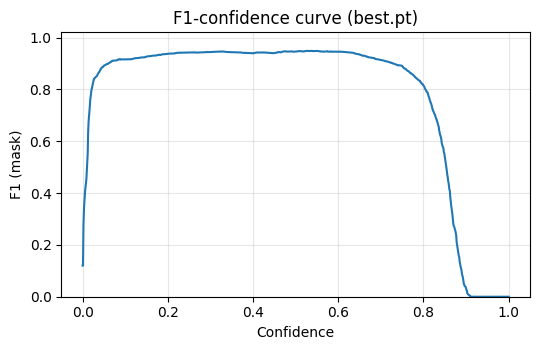

In [11]:
rows = []
for sz in (640, 1280, 1920):
    m = best.val(data=str(WORK_DIR/'data.yaml'), split='val', imgsz=sz, plots=False, verbose=False)
    rows.append(dict(imgsz=sz, box_P=m.box.mp, box_R=m.box.mr, box_mAP50=m.box.map50, box_mAP50_95=m.box.map, mask_P=m.seg.mp, mask_R=m.seg.mr, mask_mAP50=m.seg.map50, mask_mAP50_95=m.seg.map))
rs = pd.DataFrame(rows).round(3); display(rs); rs.to_csv(OUT_DIR/f'{RUN_NAME}_imgsz_sensitivity.csv', index=False)
plt.figure(figsize=(5.5, 3.6)); plt.plot(m_best.seg.px, m_best.seg.f1_curve.mean(0)); plt.xlabel('Confidence'); plt.ylabel('F1 (mask)')
plt.title('F1-confidence curve (best.pt)'); plt.ylim(0, 1.02); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 10. Qualitative inspection

Ground truth (red) and prediction (green, confidence ≥ 0.5) for every failure and for a random sample of validation images.

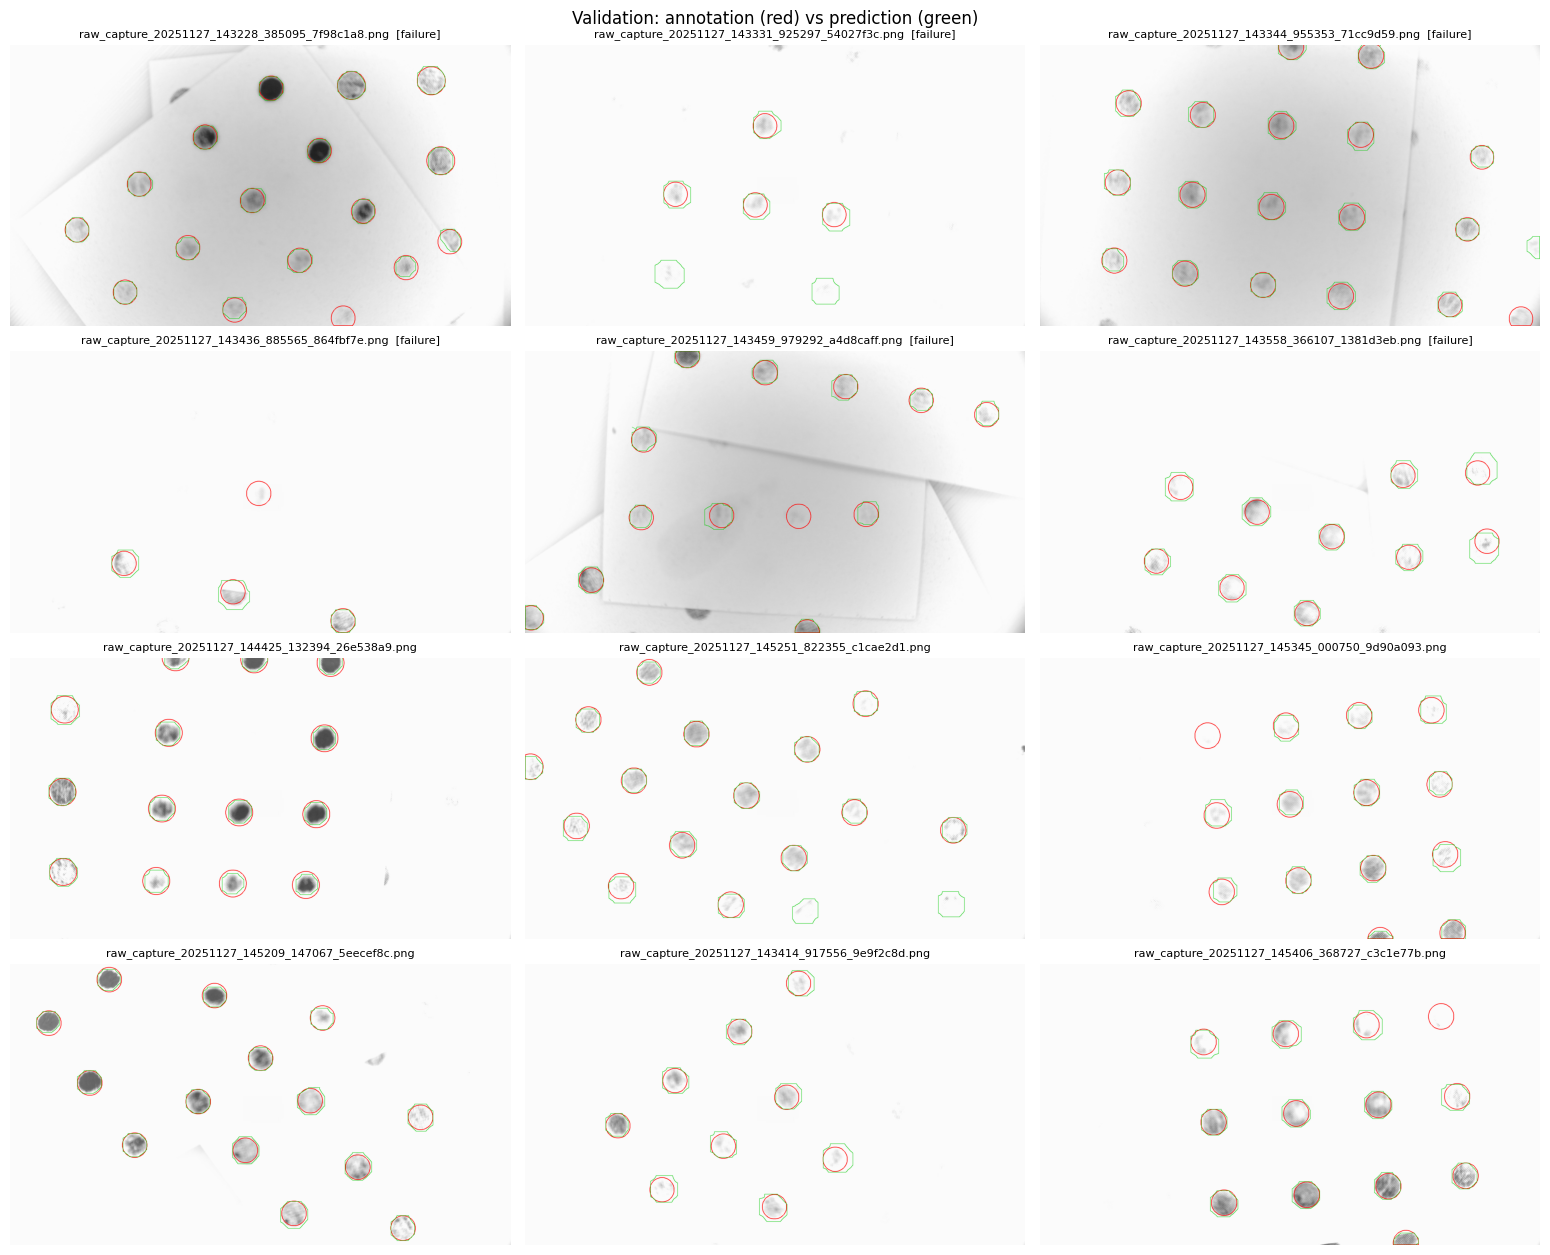

In [12]:
def pred_overlay(p):
    r = best.predict(str(p), conf=CONF, imgsz=IMGSZ, verbose=False)[0]
    im = overlay(p, WORK_DIR/'labels'/'val'/f'{Path(p).stem}.txt', th=3)
    if r.masks is not None:
        for poly in r.masks.xy: cv2.polylines(im, [poly.astype(np.int32)], True, (0,200,0), 2)
    return im
bad = list(det[(det.fp>0)|(det.fn>0)].image)[:6]; ok = [n for n in det.image if n not in bad]
rng = np.random.RandomState(SEED); sel = bad + list(rng.choice(ok, min(6, len(ok)), replace=False))
grid([(pred_overlay(WORK_DIR/'images'/'val'/n), n + ('  [failure]' if n in bad else '')) for n in sel], 'Validation: annotation (red) vs prediction (green)')

## 11. Optional: grouped K-fold cross-validation

A single split of a few dozen images gives wide uncertainty. This optional section re-trains on `K` folds of the corrected pool (training + validation images with labels); identical images (same SHA-256) are kept in one fold. It costs about `K` times Section 7. Set `RUN_KFOLD = True` in Section 1 to run it.

In [13]:
if RUN_KFOLD:
    from sklearn.model_selection import GroupKFold
    K = 5
    pool = kept.copy(); pool['sha'] = [inv.loc[(inv.split==a)&(inv.stem==b),'sha'].iloc[0] for a, b in zip(pool.split, pool.stem)]
    pool['group'] = pool.sha.astype('category').cat.codes; rows = []
    for k, (tr, va) in enumerate(GroupKFold(n_splits=K).split(pool, groups=pool.group)):
        fd = _TMP/'kfold'/f'fold{k}'
        if fd.exists(): shutil.rmtree(fd)
        for part, idx in (('train', tr), ('val', va)):
            (fd/'images'/part).mkdir(parents=True); (fd/'labels'/part).mkdir(parents=True)
            for r in pool.iloc[idx].itertuples():
                shutil.copy2(WORK_DIR/'images'/r.split/f'{r.stem}{r.ext}', fd/'images'/part/f'{r.stem}{r.ext}')
                shutil.copy2(WORK_DIR/'labels'/r.split/f'{r.stem}.txt', fd/'labels'/part/f'{r.stem}.txt')
        (fd/'data.yaml').write_text(f"path: {fd}\ntrain: images/train\nval: images/val\nnames:\n  0: {CLASS_NAME}\n")
        rk = YOLO(MODEL).train(data=str(fd/'data.yaml'), project=str(OUT_DIR/'kfold'), name=f'fold{k}', exist_ok=True, verbose=False, **{**TRAIN_CFG, 'plots': False})
        mv = YOLO(Path(rk.save_dir)/'weights'/'last.pt').val(data=str(fd/'data.yaml'), split='val', imgsz=IMGSZ, verbose=False)
        rows.append(dict(fold=k, n_val=len(va), mask_P=mv.seg.mp, mask_R=mv.seg.mr, mask_mAP50=mv.seg.map50, mask_mAP50_95=mv.seg.map))
    kf = pd.DataFrame(rows).round(3); display(kf); print(kf[['mask_P','mask_R','mask_mAP50','mask_mAP50_95']].agg(['mean','std']).round(3))
    kf.to_csv(OUT_DIR/f'{RUN_NAME}_kfold_metrics.csv', index=False)
else:
    print('K-fold skipped (RUN_KFOLD = False). Folds are evaluated with last.pt so that no checkpoint is selected on the held-out fold.')

K-fold skipped (RUN_KFOLD = False). Folds are evaluated with last.pt so that no checkpoint is selected on the held-out fold.


## 12. Inference and cropping

Reproduces the crop used by the quantification stage: every detected spot is cut out around its mask, with **5% radial padding**; pixels outside the circular region of interest are set to white (255); the crop is converted to greyscale. (Assignment of crops to the membrane grid — column, row, serum identity — is done in the existing autocropping notebook and is not repeated here.) The test folder holds full-membrane photographs; if some of them also occur in the training or validation set (Section 3) the results are illustrations only.

In [14]:
CROP_OUT = OUT_DIR/'crops_example'; CROP_OUT.mkdir(exist_ok=True)
def circular_crop(img_bgr, mask_poly, pad=0.05):
    (cx, cy), rad = cv2.minEnclosingCircle(mask_poly.astype(np.float32)); R = rad*(1+pad)
    x0, y0, x1, y1 = int(cx-R), int(cy-R), int(cx+R)+1, int(cy+R)+1
    H, W = img_bgr.shape[:2]; px0, py0, px1, py1 = max(x0,0), max(y0,0), min(x1,W), min(y1,H)
    crop = img_bgr[py0:py1, px0:px1].copy()
    yy, xx = np.ogrid[py0:py1, px0:px1]; inside = (xx-cx)**2 + (yy-cy)**2 <= R**2
    crop[~inside] = 255
    g = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)          # Y = 0.299 R + 0.587 G + 0.114 B
    g[~inside] = 255
    return g
tests = [p for p in sorted(TEST_DIR.glob('*')) if p.suffix.lower() in IMG_EXT][:3] if TEST_DIR.exists() else []
for p in tests:
    r = best.predict(str(p), conf=CONF, imgsz=IMGSZ, verbose=False)[0]; im = cv2.imread(str(p))
    polys = sorted(r.masks.xy, key=lambda q: (round(q[:,1].mean()/80), q[:,0].mean())) if r.masks is not None else []
    for i, poly in enumerate(polys): cv2.imwrite(str(CROP_OUT/f'{p.stem}_spot{i:02d}.png'), circular_crop(im, poly))
    print(p.name, '->', len(polys), 'crops')
print('Example crops written to', CROP_OUT)

IMG_20260606_175557_814.jpg -> 18 crops
col11_rowAA_lux725_Negative.jpg -> 20 crops
raw_capture_20251201_104607_983967_cb2d2141.png -> 10 crops
Example crops written to /content/drive/MyDrive/DotBlot FKUB/yolo_results/crops_example


## 13. Manuscript-ready summary

Collects the effective hyper-parameters, the dataset composition and the validation metrics. Quote these values (and not notebook defaults) in the Methods and the supplementary tables; archive the CSV/JSON files with the manuscript.

In [15]:
import yaml
args = yaml.safe_load(open(RUN_DIR/'args.yaml'))
keys = ['model','epochs','imgsz','batch','workers','optimizer','lr0','lrf','momentum','weight_decay','warmup_epochs','cos_lr','amp','patience','seed','deterministic',
        'mosaic','close_mosaic','hsv_h','hsv_s','hsv_v','translate','scale','fliplr','erasing']
hp = pd.Series({k: args.get(k) for k in keys}, name='value'); display(hp.to_frame()); display(comp)
report = dict(ultralytics=ultralytics.__version__, torch=torch.__version__, hyperparameters=hp.to_dict(), dataset=comp.to_dict(),
              corrections=log.groupby('action').size().to_dict(),
              validation_best=t_best.to_dict(), validation_last=t_last.to_dict(), mask_F1_peak_best=f1_best, mask_F1_peak_last=f1_last,
              spot_level=op.to_dict('records'), imgsz_sensitivity=rs.to_dict('records'))
json.dump(report, open(OUT_DIR/f'{RUN_NAME}_report.json','w'), indent=2, default=str)
print(json.dumps(dict(best=t_best.to_dict(), last=t_last.to_dict()), indent=1)); display(op)

,value
model,yolov8n-seg.pt
epochs,50
imgsz,1920
batch,4
workers,1
optimizer,AdamW
lr0,0.0005
lrf,0.01
momentum,0.937
weight_decay,0.0001


,images,annotated_spots,background_images,spots_per_image_mean,image_share_%
split,,,,,
train,85,1090,0,12.82,68.5
val,39,525,0,13.46,31.5


{
 "best": {
  "precision": {
   "Box": 0.965,
   "Mask": 0.963
  },
  "recall": {
   "Box": 0.935,
   "Mask": 0.933
  },
  "mAP50": {
   "Box": 0.987,
   "Mask": 0.979
  },
  "mAP50-95": {
   "Box": 0.676,
   "Mask": 0.663
  }
 },
 "last": {
  "precision": {
   "Box": 0.947,
   "Mask": 0.954
  },
  "recall": {
   "Box": 0.96,
   "Mask": 0.956
  },
  "mAP50": {
   "Box": 0.986,
   "Mask": 0.983
  },
  "mAP50-95": {
   "Box": 0.664,
   "Mask": 0.655
  }
 }
}


,conf,images,gt_spots,TP,FP,FN,precision,recall,F1,images_without_error
0,0.25,39,525,512,55,13,0.903,0.975,0.938,10
1,0.50,39,525,502,22,23,0.958,0.956,0.957,17
2,0.75,39,525,421,3,104,0.993,0.802,0.887,3


### Reporting notes

* Report training/validation image counts **and** annotated-spot counts exactly as in the composition table; quote the Ultralytics version and the hyper-parameter table of Section 13 (non-listed values are defaults).
* Quote the metrics of `last.pt` together with `best.pt` (the latter is selected on the validation split) and state the evaluation resolution.
* State TP/FP/FN only together with the matching rule (mask IoU ≥ 0.5, confidence threshold, one-to-one).
* Because training and validation images come from the same membranes and sessions, the metrics describe within-dataset segmentation; they do not demonstrate generalisation to new membranes or devices.